# Backscatter vs water level and LAI

HHHH, HVHV and their ratio against the two field variables, from
`outputs/nisar_analysis_table.csv` (built by `scripts/build_analysis_table.py`).

**Timezone, resolved.** The TOA5 logger timestamps are local US/Central, not
UTC. Established from the data: mean shallow soil temperature peaks at 14-16h
and troughs at 06h at all seven stations; under UTC those would sit at 19-21h
and 11h. So acquisitions are converted UTC -> Central, and water level is
matched to within 30 minutes (median gap 7.5 min).

**The two geometries sample different times of day**: descending ~20:00 the
previous evening, ascending ~06:20 the same morning. They are never pooled.

## 1. Setup and config

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 15,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.title_fontsize': 14, 'figure.titlesize': 20,
})

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent)
            if (p / "outputs" / "nisar_analysis_table.csv").exists())
CSV = ROOT / "outputs" / "nisar_analysis_table.csv"

STAT = "mean"              # "mean" | "median" -- which 3x3 statistic
WATER_COL = "water_cm_fixedbias"   # or "water_cm" (uncorrected bias)
LAI_MAX_GAP_DAYS = 7       # drop LAI interpolated further than this from a visit

# Quality control on the logger water level. W3-CS carries 67 records between
# -100 and +1248 cm, which is not water -- 12 m of floodwater is impossible.
# Masked rather than deleted, so the gaps stay visible.
WATER_VALID_CM = (-80, 60)

# --- smoothing (same scheme as nisar_timeseries.ipynb) ---------------------
# Each TRACK repeats every 12 days; DESC only looks 6-daily because tracks 12
# and 84 interleave, and those are different geometries. Smooth within track.
SMOOTH = True
SMOOTH_BY = ["gauge_id", "track"]
SMOOTH_WINDOW = "25D"
TRACK_LS = {12: "-", 84: "--", 105: "-"}
CMAP_LAI, CMAP_WATER = "viridis", "RdYlBu"
POINT_SIZE = 70
GAUGE_MARKER = {"W3-EC": "o", "W3-CS": "s", "W4-EC": "^", "W4-CS": "v",
                "S16": "D", "R8": "P", "S0": "X"}
print("ready")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


ready


## 2. Load

In [2]:
d = pd.read_csv(CSV)
# The full 30-minute logger trace, for the timeline plot.
WATER = pd.read_csv(ROOT / "outputs" / "water_continuous_2026.csv")
WATER["ts_local"] = pd.to_datetime(WATER.ts_local)
d["acq_local"] = pd.to_datetime(d.acq_local)
HH, HV = f"hhhh_db_{STAT}", f"hvhv_db_{STAT}"
d["ratio"] = (d.ratio_db if STAT == "mean"
              else 10*np.log10(d.hhhh_lin_median / d.hvhv_lin_median))
d["lai_use"] = d.lai.where(d.lai_gap_days <= LAI_MAX_GAP_DAYS)

# Water QC, on both the matched values and the continuous trace.
lo, hi = WATER_VALID_CM
for frame in (d, WATER):
    for col in ("water_cm", "water_cm_fixedbias"):
        if col in frame:
            n_bad = ((frame[col] < lo) | (frame[col] > hi)).sum()
            frame[col] = frame[col].where(frame[col].between(lo, hi))
            if n_bad:
                print(f"  masked {n_bad} {col} values outside {WATER_VALID_CM} cm")


def smooth(data, cols, by=SMOOTH_BY, window=SMOOTH_WINDOW):
    """Rolling mean in LINEAR power -- averaging dB gives the geometric mean."""
    out = []
    for _, g in data.groupby(by, dropna=False):
        g = g.sort_values("acq_local").copy()
        r = g.set_index("acq_local")
        for col in cols:
            lin = 10 ** (r[col] / 10)
            g[f"{col}_sm"] = (10 * np.log10(
                lin.rolling(window, center=True, min_periods=1).mean())).values
        out.append(g)
    return pd.concat(out).sort_index()


if SMOOTH:
    d = smooth(d, [HH, HV, "ratio"])
    print(f"  smoothed over {SMOOTH_WINDOW} within {SMOOTH_BY}")

SERIES = [(HH, "co-pol HHHH [dB]"), (HV, "cross-pol HVHV [dB]"),
          ("ratio", "ratio HH - HV [dB]")]

print(f"{len(d)} rows | water {d[WATER_COL].notna().sum()} | "
      f"LAI<= {LAI_MAX_GAP_DAYS}d {d.lai_use.notna().sum()} | "
      f"both {(d[WATER_COL].notna() & d.lai_use.notna()).sum()}")
print(d.groupby("direction").agg(
    n=("granule","size"), water=(WATER_COL,"count"), lai=("lai_use","count"),
    hour=("acq_hour_local","mean")).round(2).to_string())

  masked 67 water_cm values outside (-80, 60) cm
  masked 67 water_cm_fixedbias values outside (-80, 60) cm
  smoothed over 25D within ['gauge_id', 'track']
266 rows | water 150 | LAI<= 7d 121 | both 121
             n  water  lai   hour
direction                        
ASC         63     32   29   6.33
DESC       203    118   92  19.94


## 3. Backscatter vs water level and LAI

Rows: the two field variables. Columns: the three backscatter quantities.
Each point is one (gauge, pass); colour is the *other* field variable, so you
can see whether a relationship holds at fixed canopy or fixed water.

saved /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/scatter_desc.png


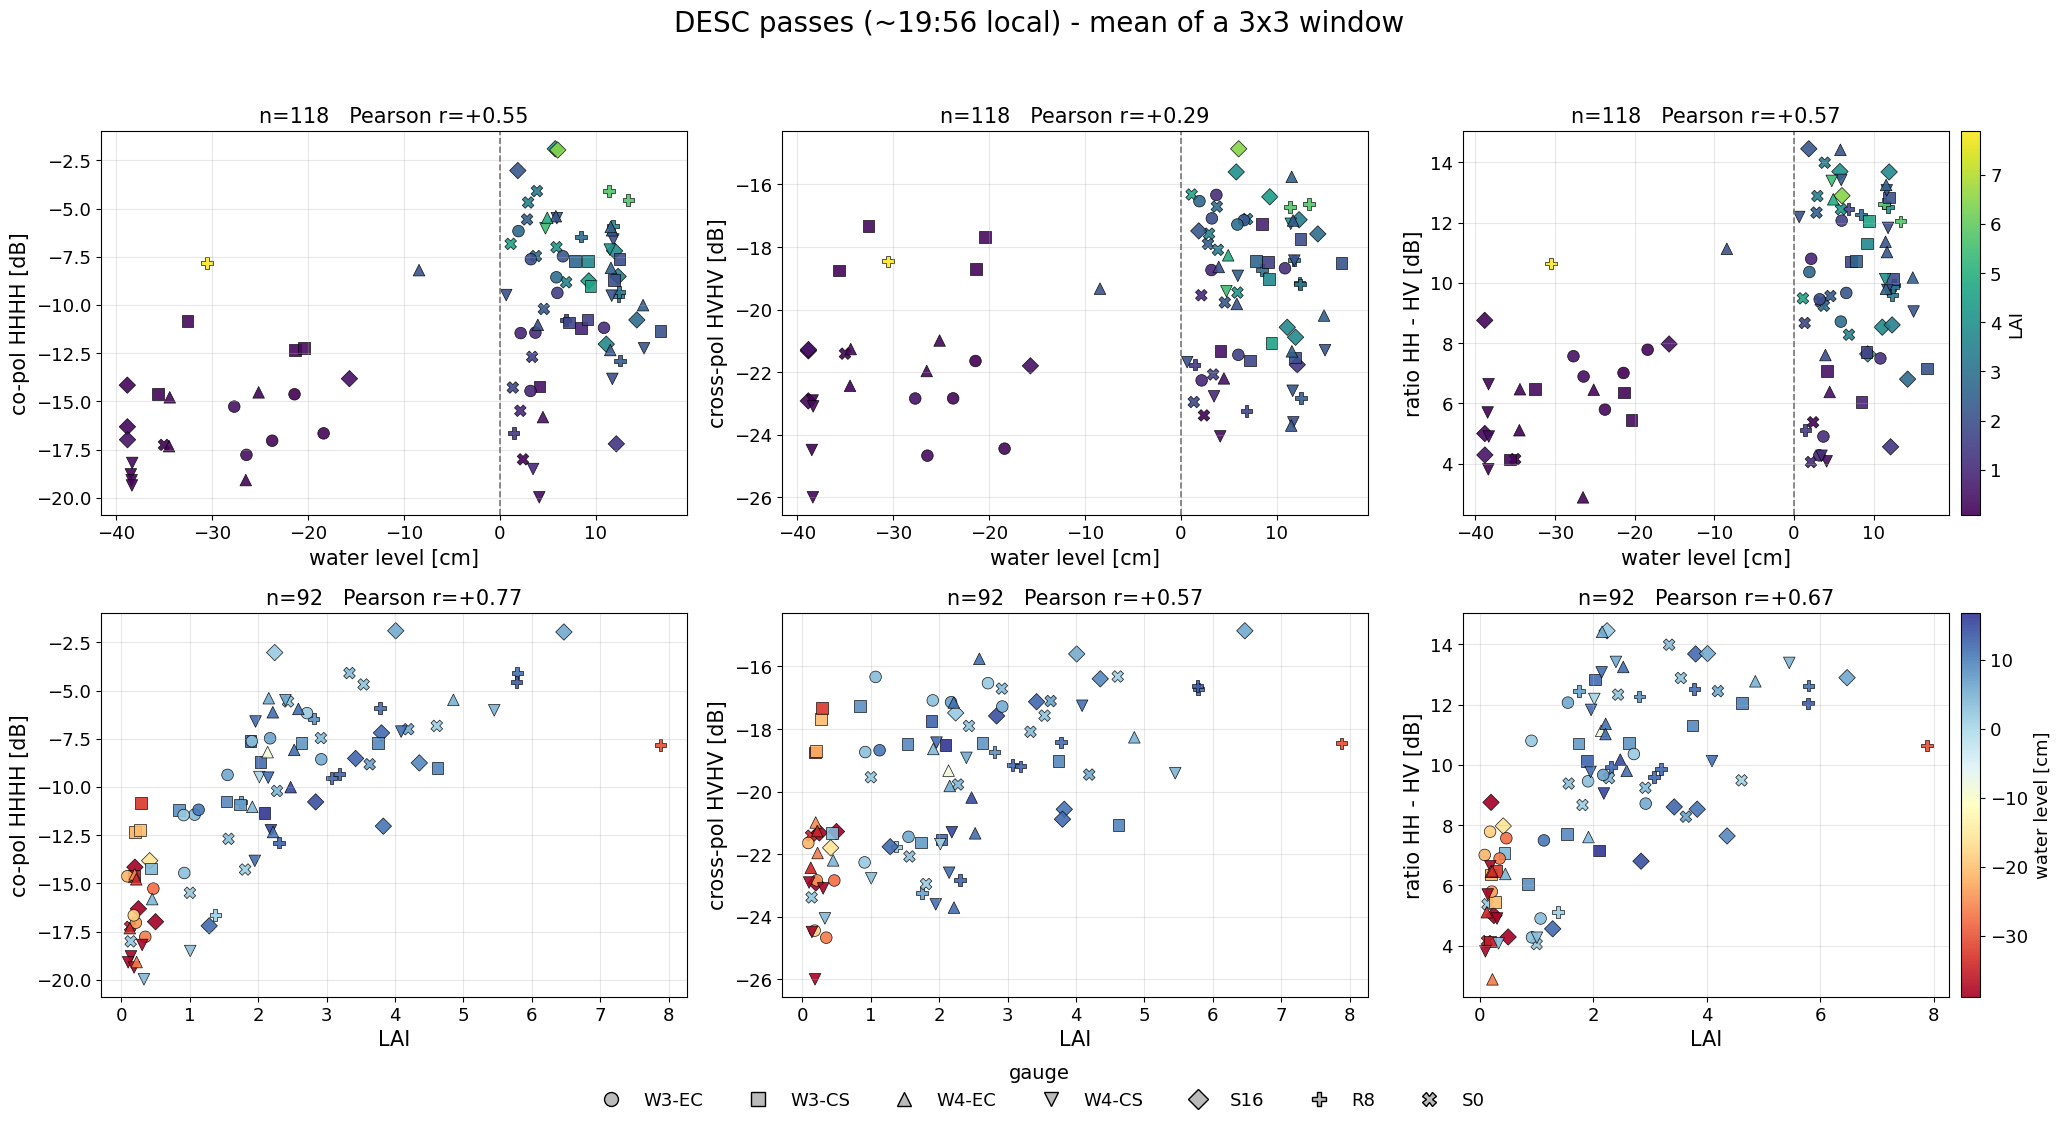

In [3]:
def scatter_grid(data, direction, save=None):
    sub = data[data.direction == direction]
    fig, axes = plt.subplots(2, 3, figsize=(21, 11))
    rows = [(WATER_COL, "water level [cm]", "lai_use", CMAP_LAI, "LAI"),
            ("lai_use", "LAI", WATER_COL, CMAP_WATER, "water level [cm]")]

    for i, (xcol, xlabel, ccol, cmap, clabel) in enumerate(rows):
        s = sub.dropna(subset=[xcol])
        for j, (ycol, ylabel) in enumerate(SERIES):
            ax = axes[i][j]
            sc = None
            for gid, g in s.groupby("gauge_id"):
                sc = ax.scatter(g[xcol], g[ycol], c=g[ccol], cmap=cmap,
                                s=POINT_SIZE, marker=GAUGE_MARKER.get(gid, "o"),
                                edgecolor="k", linewidth=0.5, alpha=0.9,
                                vmin=s[ccol].min(), vmax=s[ccol].max())
            if xcol == WATER_COL:
                # 0 cm separates standing water from a water table below surface
                ax.axvline(0, color="#777", lw=1.2, ls="--")
            ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=0.3)
            n = s[[xcol, ycol]].dropna().shape[0]
            r = s[[xcol, ycol]].corr().iloc[0, 1]
            ax.set_title(f"n={n}   Pearson r={r:+.2f}", fontsize=15)
            if sc is not None and j == 2:
                cb = fig.colorbar(sc, ax=ax, pad=0.02)
                cb.set_label(clabel, size=13)

    handles = [plt.Line2D([0],[0], marker=m, color="none", markerfacecolor="#bbb",
                          markeredgecolor="k", markersize=10, label=g)
               for g, m in GAUGE_MARKER.items()]
    fig.legend(handles=handles, loc="lower center", ncol=7, frameon=False,
               bbox_to_anchor=(0.5, -0.02), title="gauge")
    hr = sub.acq_hour_local.mean()
    fig.suptitle(f"{direction} passes (~{int(hr):02d}:{int(hr%1*60):02d} local)"
                 f" - {STAT} of a 3x3 window", y=0.995)
    fig.tight_layout(rect=[0, 0.03, 1, 0.97])
    if save: fig.savefig(save, dpi=120, bbox_inches="tight"); print("saved", save)
    return fig


scatter_grid(d, "DESC", save=ROOT/"outputs"/"scatter_desc.png"); plt.show()

saved /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/scatter_asc.png


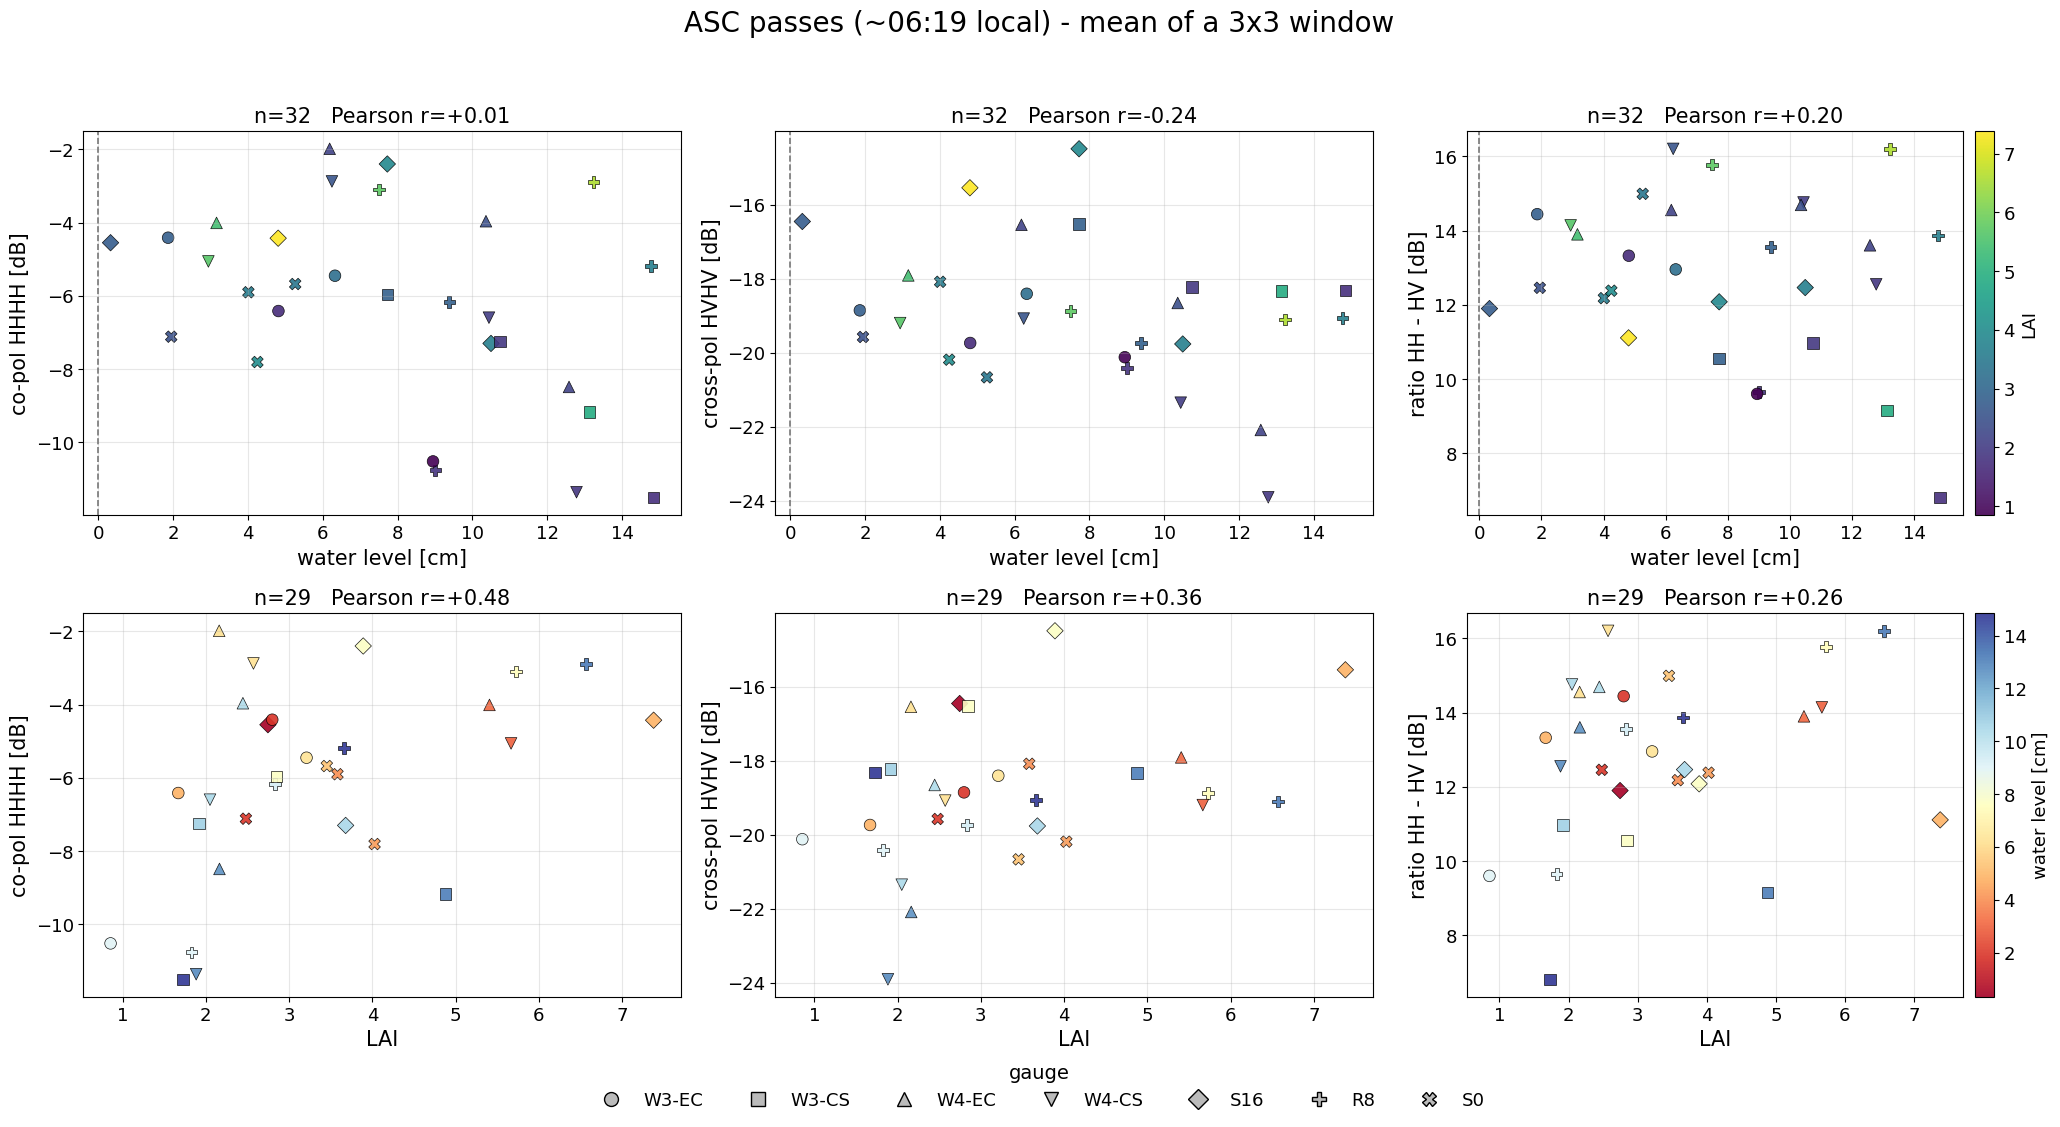

In [4]:
scatter_grid(d, "ASC", save=ROOT/"outputs"/"scatter_asc.png"); plt.show()

## 4. Everything on one time axis, per gauge

Backscatter, water level and LAI together, so you can see what the fields were
doing when each pass happened. Water is the full 30-minute logger trace, not
just the matched points.

saved /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/timeline_all.png


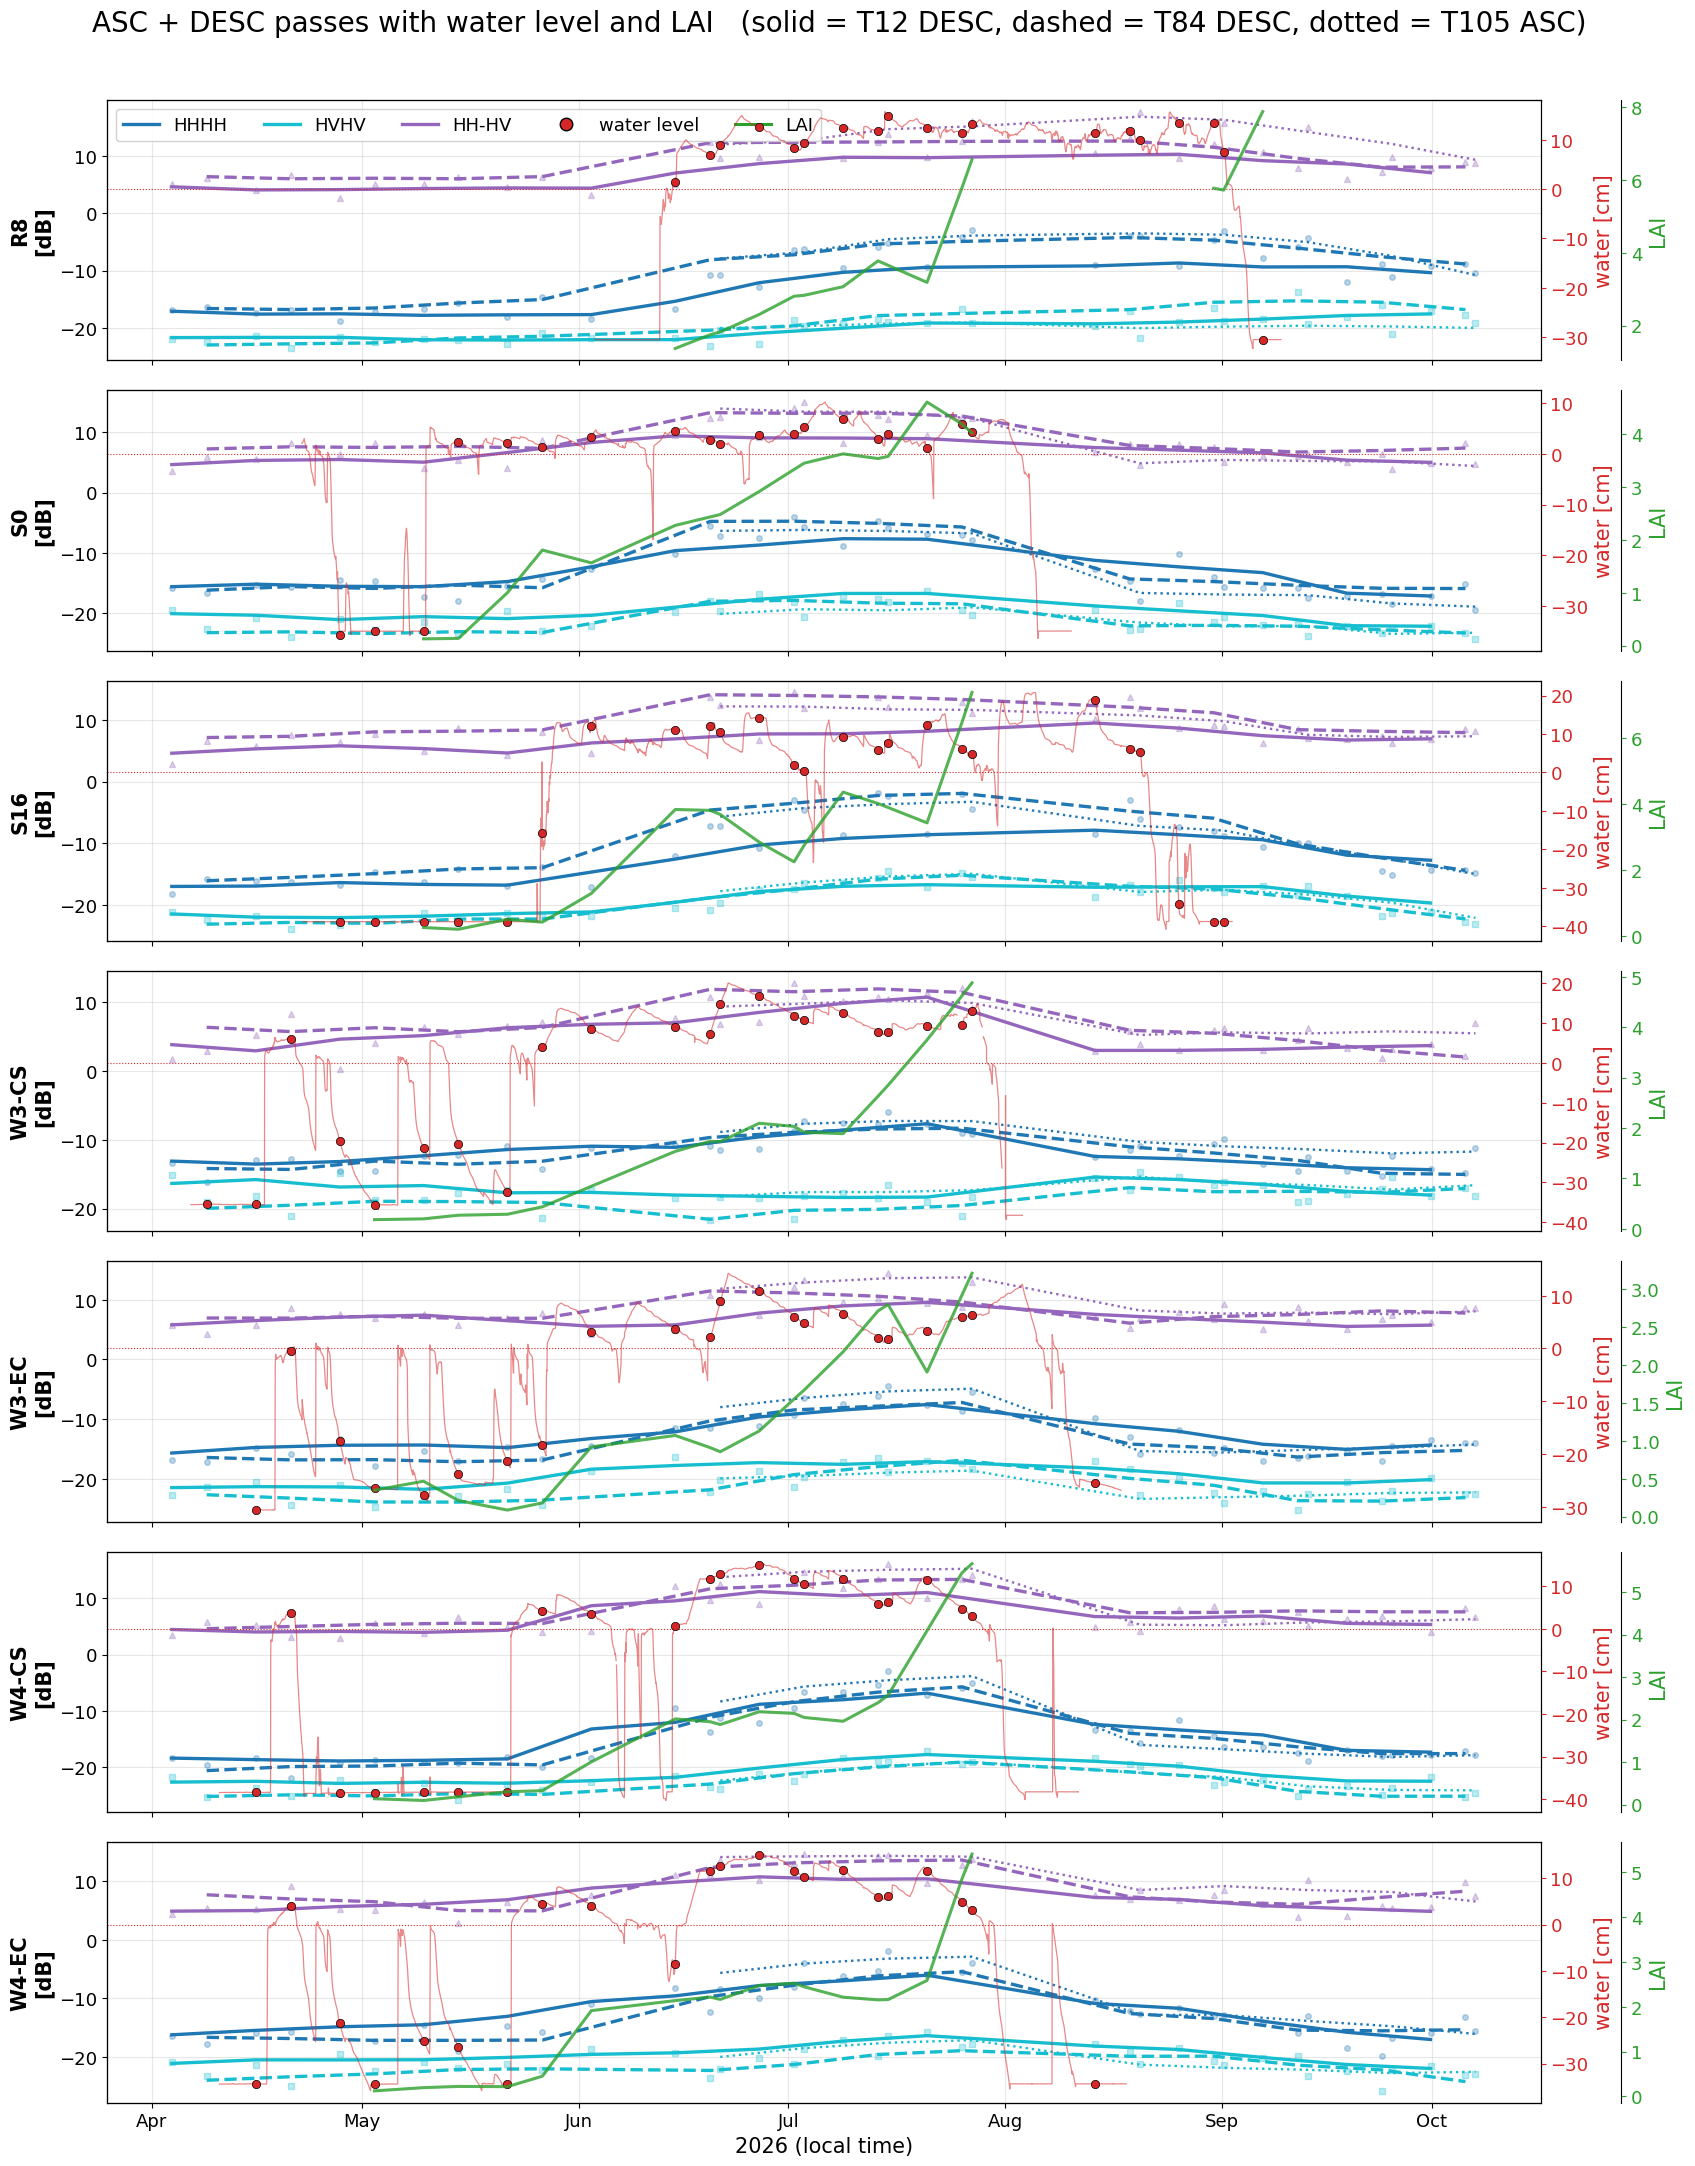

In [5]:
def timeline(data, direction=None, save=None):
    """Per-gauge timeline. direction=None shows ASC and DESC together.

    The geometries are distinguished by LINE STYLE and never merged:
      solid   DESC track 12      dashed  DESC track 84      dotted  ASC track 105
    ASC samples ~06:20 local, DESC ~19:56, so they differ in time of day as
    well as look angle. Section 7 quantifies the offset.
    """
    sub = data if direction is None else data[data.direction == direction]
    gauges = sorted(sub.gauge_id.unique())
    fig, axes = plt.subplots(len(gauges), 1, figsize=(17, 3.1*len(gauges)),
                             sharex=True)
    LS = {(12, "DESC"): "-", (84, "DESC"): "--", (105, "ASC"): ":"}

    for ax, gid in zip(np.atleast_1d(axes), gauges):
        g = sub[sub.gauge_id == gid].sort_values("acq_local")
        spec = [(HH, "#1f77b4", "o", "HHHH"), (HV, "#17becf", "s", "HVHV"),
                ("ratio", "#9467bd", "^", "HH-HV")]
        for col, c_, mk, lab in spec:
            smcol = f"{col}_sm"
            if SMOOTH and smcol in g:
                ax.plot(g.acq_local, g[col], mk, color=c_, ms=4, alpha=0.30)
                first = True
                for (tr, dr), gt in g.groupby(["track", "direction"]):
                    gt = gt.sort_values("acq_local")
                    ax.plot(gt.acq_local, gt[smcol], color=c_,
                            lw=1.7 if dr == "ASC" else 2.4,
                            ls=LS.get((tr, dr), "-"),
                            label=lab if first else None)
                    first = False
            else:
                ax.plot(g.acq_local, g[col], mk + "-", color=c_, ms=5, lw=1.6,
                        label=lab)
        ax.set_ylabel(f"{gid}\n[dB]", fontweight="bold")
        ax.grid(alpha=0.3)

        ax2 = ax.twinx()
        w = WATER[WATER.gauge_id == gid].sort_values("ts_local")
        ax2.plot(w.ts_local, w[WATER_COL], "-", color="#d62728", lw=0.9,
                 alpha=0.55)
        ax2.plot(g.acq_local, g[WATER_COL], "o", color="#d62728", ms=6,
                 markeredgecolor="k", markeredgewidth=0.5, zorder=5)
        ax2.axhline(0, color="#d62728", lw=0.8, ls=":")
        ax2.set_ylabel("water [cm]", color="#d62728")
        ax2.tick_params(axis="y", colors="#d62728")

        ax3 = ax.twinx(); ax3.spines.right.set_position(("outward", 58))
        ax3.plot(g.acq_local, g.lai_use, "-", color="#2ca02c", lw=2.2, alpha=0.8)
        ax3.set_ylabel("LAI", color="#2ca02c")
        ax3.tick_params(axis="y", colors="#2ca02c")

    a0 = np.atleast_1d(axes)[0]
    h1, l1 = a0.get_legend_handles_labels()
    a0.legend(h1 + [plt.Line2D([0], [0], marker="o", color="none",
                               markerfacecolor="#d62728", markersize=9),
                    plt.Line2D([0], [0], color="#2ca02c", lw=2.2)],
              l1 + ["water level", "LAI"], ncol=5, loc="upper left",
              framealpha=0.9)
    last = np.atleast_1d(axes)[-1]
    last.xaxis.set_major_locator(mdates.MonthLocator())
    last.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    last.set_xlabel("2026 (local time)")
    fig.suptitle(f"{'ASC + DESC' if direction is None else direction} passes "
                 f"with water level and LAI   "
                 f"(solid = T12 DESC, dashed = T84 DESC, dotted = T105 ASC)",
                 y=0.999)
    fig.tight_layout(rect=[0, 0, 1, 0.99])
    if save:
        fig.savefig(save, dpi=120, bbox_inches="tight"); print("saved", save)
    return fig


timeline(d, None, save=ROOT / "outputs" / "timeline_all.png")
plt.show()

## 5. Correlations, by direction

In [6]:
rows = []
for direction, s in d.groupby("direction"):
    for xcol, xname in [(WATER_COL, "water_cm"), ("lai_use", "LAI")]:
        for ycol, yname in [(HH, "HHHH"), (HV, "HVHV"), ("ratio", "HH-HV")]:
            v = s[[xcol, ycol]].dropna()
            rows.append({"direction": direction, "x": xname, "y": yname,
                         "n": len(v),
                         "pearson_r": round(v.corr().iloc[0, 1], 3) if len(v) > 2 else np.nan,
                         "spearman_r": round(v.corr("spearman").iloc[0, 1], 3) if len(v) > 2 else np.nan})
pd.DataFrame(rows)

,direction,x,y,n,pearson_r,spearman_r
0,ASC,water_cm,HHHH,32,0.006,-0.256
1,ASC,water_cm,HVHV,32,-0.235,-0.334
2,ASC,water_cm,HH-HV,32,0.195,0.036
3,ASC,LAI,HHHH,29,0.475,0.480
4,ASC,LAI,HVHV,29,0.359,0.325
5,ASC,LAI,HH-HV,29,0.261,0.230
6,DESC,water_cm,HHHH,118,0.555,0.546
7,DESC,water_cm,HVHV,118,0.290,0.293
8,DESC,water_cm,HH-HV,118,0.572,0.557
9,DESC,LAI,HHHH,92,0.769,0.824


## Caveats

- **n is small.** 125 rows have both variables, spread over 7 gauges and two
  geometries, and the four Way fields are within 0.7 km of each other -- they
  are not independent samples.
- **LAI is interpolated** between weekly visits, filtered here to within
  `LAI_MAX_GAP_DAYS` of a real measurement. Raise or lower it and the n
  changes.
- **Water level merges two measurements**: positive is flood depth above soil,
  negative is water table below surface from the pipe. The dashed line at 0 cm
  marks the switch; it is not a continuous instrument across that boundary.
- **Correlation here pools gauges**, so between-field differences and
  within-field seasonality are mixed together. A per-gauge or mixed-effects
  treatment would separate them.
- **3x3 window at 10 m.** Re-run the extractor with `--window 1` and `5` to see
  how much of the scatter is speckle.


## 6. C-band diagnostic analogue

`ndvi_error_diagnostic.ipynb` showed true-dry samples misclassified as wet
concentrating at high NDVI -- the C-band penetration ceiling. The analogue here
uses the **same dry threshold (water level < -1 cm)** and asks whether the
L-band quantities separate the classes as the canopy closes.

**These are not the same samples.** That diagnostic is 2021-2024, fields 1-55,
with out-of-fold model predictions. This is 2026, the 7 Runkle plots, no model.
Nothing can be overlaid; only the structure is shared. LAI stands in for NDVI,
since 2026 has no Sentinel-2 series here.


DESC: 118 samples | dry 41 wet 77

class counts per canopy bin -- the dry class empties out as LAI rises:
cls      dry  wet
lai_bin          
(0, 1]    22    7
(1, 2]     0   17
(2, 4]     1   33
(4, 10]    1   11


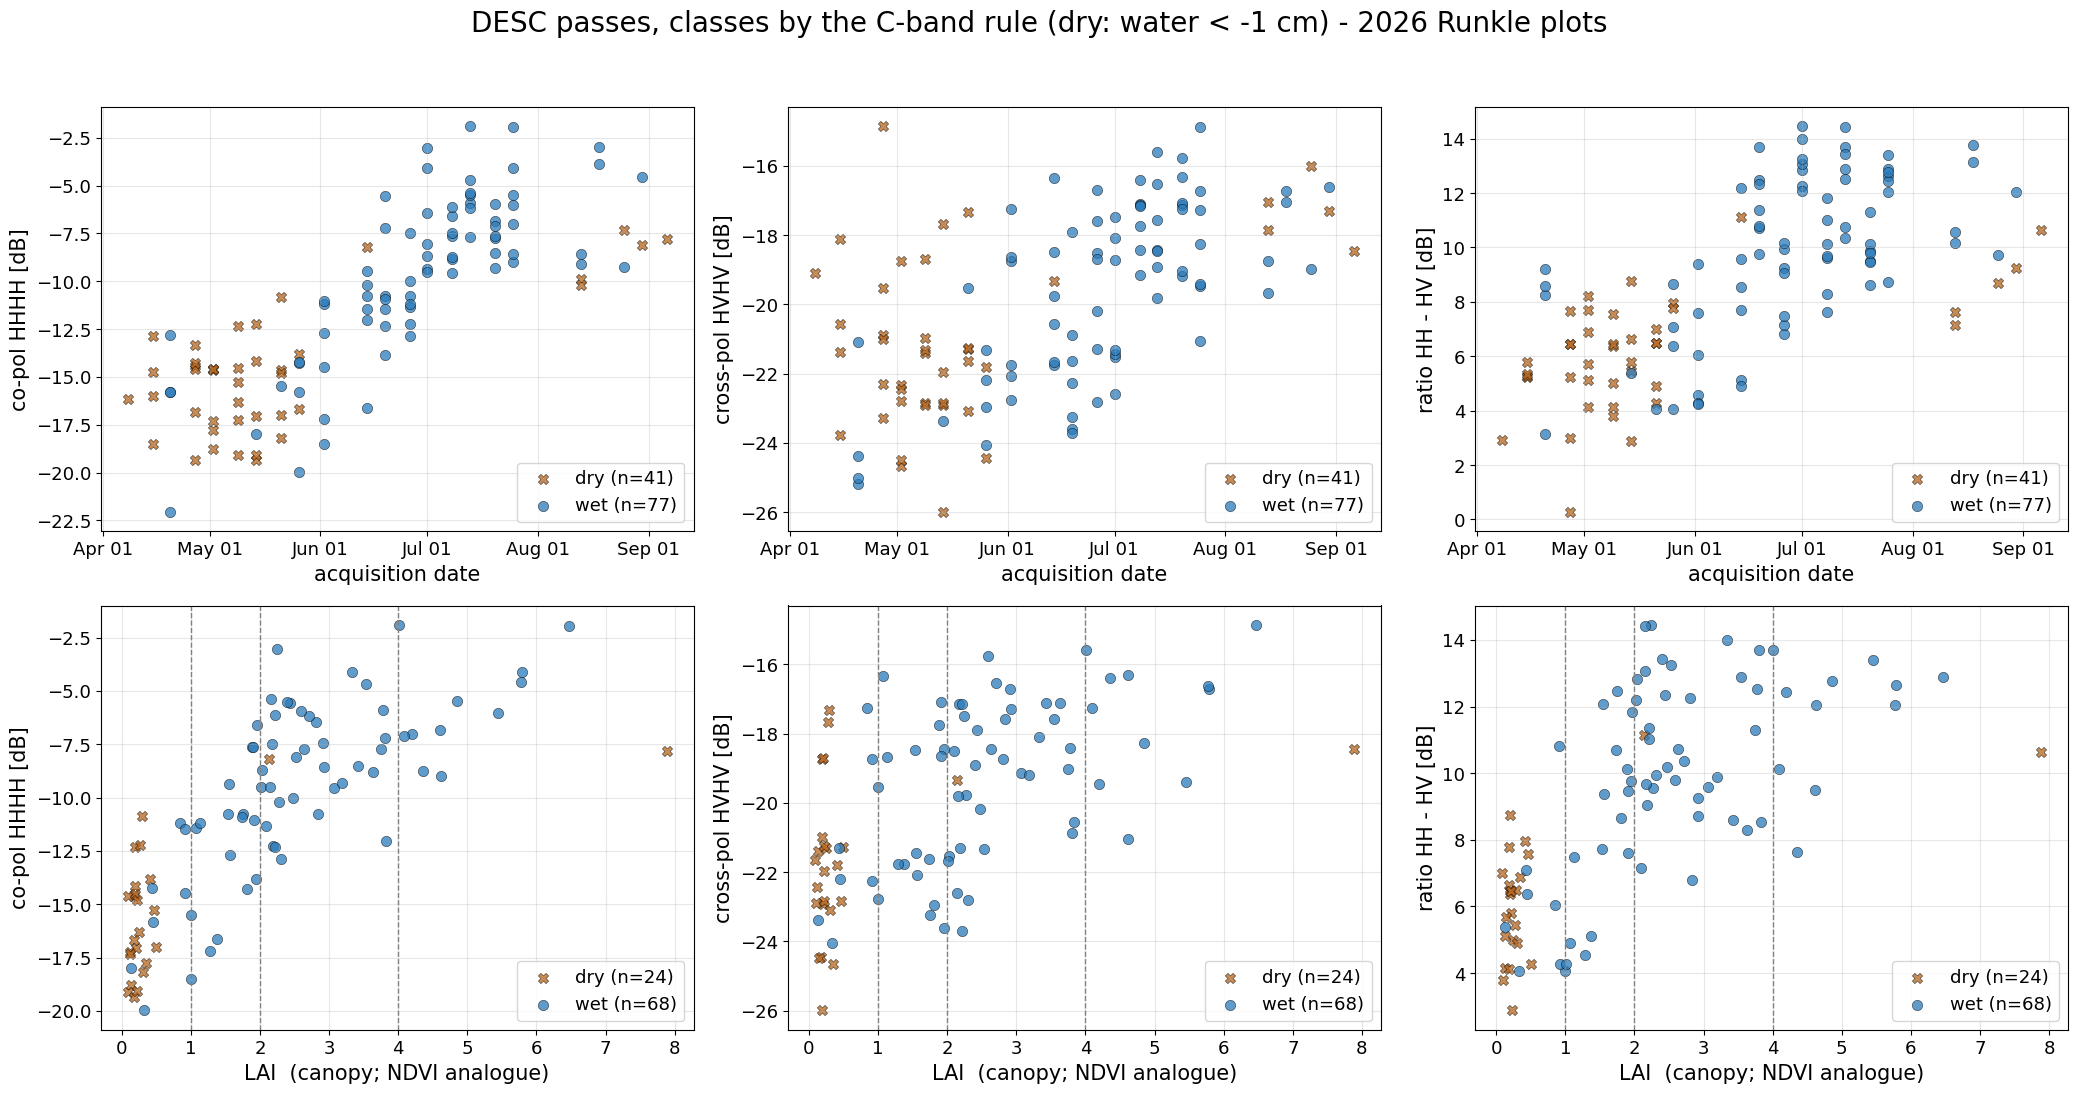

In [7]:

DRY_THRESHOLD = -1          # same as ndvi_error_diagnostic.ipynb
DIR = "DESC"                # ASC has 1 dry sample in 32 -- not usable

q = d[(d.direction == DIR) & d[WATER_COL].notna()].copy()
q["true"] = np.where(q[WATER_COL] < DRY_THRESHOLD, 0, 1)
q["cls"] = q.true.map({0: "dry", 1: "wet"})
q["doy_plot"] = pd.to_datetime("2000-" + q.acq_local.dt.strftime("%m-%d"))

print(f"{DIR}: {len(q)} samples | dry {int((q.true==0).sum())} "
      f"wet {int((q.true==1).sum())}")
LAI_BINS = [0, 1, 2, 4, 10]
q["lai_bin"] = pd.cut(q.lai_use, LAI_BINS)
print("\nclass counts per canopy bin -- the dry class empties out as LAI rises:")
print(pd.crosstab(q.lai_bin, q.cls).to_string())

COL = {"dry": "#b5651d", "wet": "#2b7bba"}
PANELS = [(HH, "co-pol HHHH [dB]"), (HV, "cross-pol HVHV [dB]"),
          ("ratio", "ratio HH - HV [dB]")]

fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for j, (col, ylab) in enumerate(PANELS):
    ax = axes[0][j]                                  # vs date
    for cl, g in q.groupby("cls"):
        ax.scatter(g.doy_plot, g[col], s=55, color=COL[cl], alpha=0.75,
                   marker="o" if cl == "wet" else "X",
                   edgecolor="k", linewidth=0.4, label=f"{cl} (n={len(g)})")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.set_xlabel("acquisition date"); ax.set_ylabel(ylab)
    ax.grid(alpha=0.3); ax.legend(loc="lower right")

    ax = axes[1][j]                                  # vs canopy
    s = q.dropna(subset=["lai_use"])
    for cl, g in s.groupby("cls"):
        ax.scatter(g.lai_use, g[col], s=55, color=COL[cl], alpha=0.75,
                   marker="o" if cl == "wet" else "X",
                   edgecolor="k", linewidth=0.4, label=f"{cl} (n={len(g)})")
    for b in LAI_BINS[1:-1]:
        ax.axvline(b, color="grey", lw=1, ls="--")
    ax.set_xlabel("LAI  (canopy; NDVI analogue)"); ax.set_ylabel(ylab)
    ax.grid(alpha=0.3); ax.legend(loc="lower right")

fig.suptitle(f"{DIR} passes, classes by the C-band rule "
             f"(dry: water < {DRY_THRESHOLD} cm) - 2026 Runkle plots", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(ROOT/"outputs"/"cband_analogue.png", dpi=120, bbox_inches="tight")
plt.show()


In [8]:

# Separation between classes per canopy bin: the quantity the C-band
# diagnostic found collapsing at high NDVI. Reported only where BOTH classes
# have samples -- which in 2026 is the lowest bin alone.
rows = []
for b, g in q.dropna(subset=["lai_use"]).groupby("lai_bin", observed=False):
    w, dr = g[g.true == 1], g[g.true == 0]
    r = {"lai_bin": str(b), "n_dry": len(dr), "n_wet": len(w)}
    for col, name in [(HH, "HHHH"), (HV, "HVHV"), ("ratio", "HH-HV")]:
        r[f"d_{name}"] = (round(w[col].mean() - dr[col].mean(), 2)
                          if len(w) > 1 and len(dr) > 1 else np.nan)
    rows.append(r)
sep = pd.DataFrame(rows)
print("wet minus dry, dB (NaN = one class has <2 samples):")
sep


wet minus dry, dB (NaN = one class has <2 samples):


,lai_bin,n_dry,n_wet,d_HHHH,d_HVHV,d_HH-HV
0,"(0, 1]",22,7,0.94,0.54,0.4
1,"(1, 2]",0,17,NaN,NaN,NaN
2,"(2, 4]",1,33,NaN,NaN,NaN
3,"(4, 10]",1,11,NaN,NaN,NaN



### What this can and cannot answer

The C-band diagnostic's finding was about **true-dry samples at high canopy**.
In 2026 that cell of the design is empty: 0 dry samples at LAI 1-2, 1 at 2-4,
1 at >4. So the separation column is computable only in the lowest canopy bin,
and nothing here tests the penetration ceiling.

Two reasons the cell is empty, worth separating:

1. **Management** -- these fields are held flooded from flood-up to drain-down,
   so wet is the normal state once the canopy exists.
2. **Instrumentation** -- loggers stop between 3 Aug and 9 Sep while passes run
   to 7 Oct, so the drain-down, the one period that is both dry and
   high-canopy, is mostly unrecorded.

The second is fixable: water level over the drain-down would populate exactly
the cell that matters. The 2026 passes already exist.
